# 05 · Robustness: thematic vs. non-thematic name changes (control group)
> Run after notebooks 01–04, from inside the `code` folder. Raw inputs are in `data/` (described in notebook 01).
> Research questions: top of notebook 03.

**Why this notebook?** Notebook 03 shows that Dot-com renames earned a large positive CAR. But *any* corporate
name change can move the stock: it often comes with a merger, a new strategy or a new management team. Without a
benchmark we cannot tell whether the market rewarded the **buzzword** or just the **rename**. This notebook adds
that benchmark.

**Question.** Do thematic (buzzword) renames earn higher abnormal returns than non-thematic renames of listed
firms in the same wave years?
$$\Delta_k = \overline{CAR}^{\,thematic}_k - \overline{CAR}^{\,non\text{-}thematic}_k$$

| Step | What happens |
|---|---|
| 0 | Settings (same design as notebooks 03 / 04) |
| 1 | Load the name changes (notebook 02), the thematic events and the CRSP daily data |
| 2 | **Control group**: non-thematic renames in the same wave years (funnel of exclusions) |
| 3 | Firm characteristics and **exploratory data analysis** of both groups (Tutorial 4) |
| 4 | Event study with the shared module `buzzword_event_study.py`, on the **CRSP effective date** for both groups |
| 5 | Thematic − non-thematic: bootstrap, Welch t and Mann-Whitney tests per wave |
| 6 | OLS with a thematic dummy, year fixed effects and firm controls (Tutorial 4 preprocessing pipeline) |
| 7 | Size-matched controls (same wave and year, nearest market cap, each control used once) |
| 8 | Export and summary |

### Design choices
* **Control renames** come from `all_name_changes.csv` (notebook 02): every change of the *core* company name of
  a listed CRSP common stock (NYSE, NYSE American, Nasdaq), keyed by PERMNO. We drop renames whose old **or** new
  name contains any buzzword of the dictionary (so theme entries, exits and re-wordings all leave the control
  group), SPAC shells renamed to another shell (`ACQ`/`ACQUISITION` in the new name, the same rule as for the
  thematic events), and renames of firms that have a thematic rename within ±365 days (their returns would mix
  both events).
* **Deal types.** The thematic side uses the hand-coded `deal_type` of notebook 02: the main comparison
  keeps **cosmetic renames and pivots (a/b)**; thematic de-SPAC closings (d) are compared separately; mergers (c)
  and other bundled news (e) are left out. The 4,090 control renames cannot be hand-coded, so for them the only
  available proxy is the former-SPAC flag (old name an "Acquisition" shell or SIC 6799 = SPAC-related). Control renames
  that follow an ordinary merger stay in the control group; this is a stated limitation (it can move the
  control mean either way).
* **Same waves:** controls are taken from the wave periods (Dot-com 1995–2002, Blockchain 2016–2020,
  AI 2021–2025) and compared with the thematic renames **inside** the same period. Year fixed effects and
  same-year matching remove differences in market conditions within a wave.
* **Same event date for both groups.** Verified announcement dates exist only for the thematic events,
  so the comparison uses the **CRSP effective date for both groups**. This is an **implementation-date
  comparison**: it measures the reaction when the new name takes effect, often weeks after the news. Comparing
  thematic renames on an earlier date with controls on their effective date would mix two information events,
  so it is not done. The
  announcement-date response of the thematic renames is reported in notebook 03 and is **not** compared with the
  controls.
* **Blockchain:** only 2 thematic renames fall inside 2016–2020, so no Blockchain test is possible; the controls
  are still shown for completeness.

## Step 0: Settings

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import buzzword_event_study as es

np.random.seed(42)
random_state = 42
rng = np.random.default_rng(random_state)
set_config(transform_output="pandas")  # sklearn transformers return DataFrames
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rc("axes", titlesize=12, labelsize=11)

In [2]:
# ---- paths: run the notebooks from inside the code/ folder ----
base_dir = Path.cwd().parent                                  # project folder (the notebooks run from code/)
data_dir = base_dir / "data"                                  # raw input files (described in notebook 01)
wrds_dir = data_dir / "raw_data" / "wrds"                     # raw WRDS extracts
edgar_dir = data_dir / "raw_data" / "edgar_fts"               # EDGAR full-text search extract
event_dates_dir = data_dir / "event_dates"                    # hand-collected dates + SEC scan results (inputs)
event_dates_out_dir = base_dir / "event_dates"                # event-date table produced by notebook 02
processed_dir = base_dir / "processed"                        # intermediate tables passed between notebooks
output_dir = base_dir / "output"                              # result tables and figures
for folder in [processed_dir, output_dir, event_dates_out_dir, edgar_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- study design ----
study_start_year, study_end_year = 1990, 2025
eligible_exchanges = ["N", "A", "Q"]            # NYSE, NYSE American, Nasdaq
themes = ["Dot-com", "Blockchain", "AI"]         # Dot-com first = reference category in RQ3
theme_colors = {"Dot-com": "#2a78b5", "Blockchain": "#e08a1e", "AI": "#3a9e5f"}
wave_periods = {"Dot-com": (1995, 2002), "Blockchain": (2016, 2020), "AI": (2021, 2025)}
wave_reference_year = {"Dot-com": 1995, "Blockchain": 2017, "AI": 2022}   # Netscape IPO, Bitcoin boom, ChatGPT

# event-study design (estimation window, windows, tests): see buzzword_event_study.py

# ---- control-group design ----
groups = ["thematic", "non-thematic"]
group_colors = {"thematic": "#c0392b", "non-thematic": "#7f7f7f"}
control_exclusion_days = 365      # drop control renames of firms with a thematic rename within one year
n_matched_controls = 3            # size-matched controls per thematic event (same wave and year, no reuse)
control_daily_file = wrds_dir / "crsp_daily_rename_firms.csv.gz"

### Keyword dictionary
Copied unchanged from notebook 02, so that "non-thematic" means exactly "no buzzword of our dictionary in the old
or the new name".

In [3]:
legal_suffix = r"(?:INC|CORP|CORPORATION|CO|LTD|HOLDINGS?|HLDGS|GROUP|GRP)"
theme_patterns = {
    "Blockchain": [r"\bBLOCKCHAIN\b", r"\bBITCOIN\b", r"\bCRYPTO\w*", r"\bDIGITAL ASSETS?\b",
                   r"\bDISTRIBUTED LEDGER\b", r"\bWEB ?3\b", r"\bTOKEN\b"],
    "AI": [r"\bAI\b",
           r"(?<!\b[A-Z] )\bA I\b(?! [A-Z]\b)",       # CRSP's "A I" but not initials such as "L A I"
           r"\bARTIFICIAL INTEL\w*"],
    "Dot-com": [rf"\bCOM\b(?= {legal_suffix}\b|$)",     # CRSP's ".com": "XCELERA COM INC", "HOTELS COM"
                r"\bDOT ?COM\b", r"\bINTERNET\b", r"\bONLINE\b", r"\bWEB\b(?! ?3)",
                r"\bE ?COMMERCE\b", r"\bCYBER\b"],
}
theme_priority = ["Blockchain", "AI", "Dot-com"]
theme_first_year = {"Dot-com": 1994, "Blockchain": 2009, "AI": 2015}
spac_shell_pattern = r"\bACQ(?:UISITION)?\b"

# Event IDs to drop after manual review of SEC filings (fill in with a reason, before looking at returns)
manual_exclusions = {}   # e.g. {"permno_12345_2000-01-01": "name refers to communications, not .com"}


def match_theme(name, theme):
    """
    Check whether a company name contains one of the theme's keywords.

    Parameters
    ----------
    name : str
        Cleaned company name.
    theme : str
        "Dot-com", "Blockchain" or "AI".

    Returns
    -------
    bool
    """
    return any(re.search(pattern, name) for pattern in theme_patterns[theme])

## Step 1: Load the inputs
* `processed/all_name_changes.csv` (notebook 02): all 6,772 core-name changes of listed common stocks 1990–2025.
* `processed/events.csv` (notebook 02): the 97 thematic events.
* Daily CRSP data: `crsp_daily_event_firms.csv.gz` (thematic firms, notebook 02) and
  `crsp_daily_rename_firms.csv.gz` (all renaming firms 1994–2025, a window from 400 calendar days before to 30
  days after each name change). Both files are described in notebook 01.

In [4]:
date_columns = ["effective_date", "event_date", "public_announcement_date", "earliest_recorded_date"]
thematic_events = pd.read_csv(processed_dir / "events.csv", parse_dates=date_columns)
all_changes = pd.read_csv(processed_dir / "all_name_changes.csv", parse_dates=["change_date"])
daily = pd.concat([es.load_daily(wrds_dir / "crsp_daily_event_firms.csv.gz"), es.load_daily(control_daily_file)]) \
    .drop_duplicates(["permno", "date"]).sort_values(["permno", "date"]).reset_index(drop=True)
market = es.load_market(wrds_dir / "crsp_daily_market_index.csv.gz")
for name, table in {"thematic events": thematic_events, "all name changes": all_changes,
                    "daily (both groups)": daily, "market": market}.items():
    print(f"  {name:<20} {table.shape[0]:>10,} rows x {table.shape[1]} cols")

/Users/chunhanliao/Documents/FS_MADS/1_IntroDA/Group Project/IDA_Group7_whats_in_a_buzzword_submission/code/buzzword_event_study.py:94: DtypeWarning: Columns (8: dlyretmissflg) have mixed types. Specify dtype option on import or set low_memory=False.
  daily = pd.read_csv(target_file)


  thematic events              97 rows x 23 cols
  all name changes          6,772 rows x 7 cols
  daily (both groups)   3,050,022 rows x 12 cols
  market                    9,572 rows x 5 cols


## Step 2: Control group of non-thematic renames
The funnel shows how many name changes each rule removes. Every rule is fixed before looking at returns.

In [5]:
def assign_wave(years):
    """
    Map calendar years to the wave period they fall in.

    Parameters
    ----------
    years : pandas.Series
        Calendar years.

    Returns
    -------
    pandas.Series
        "Dot-com", "Blockchain", "AI" or ``None`` (outside every wave period).
    """
    wave = pd.Series(None, index=years.index, dtype=object)
    for theme, (first, last) in wave_periods.items():
        wave[years.between(first, last)] = theme
    return wave


def build_control_sample(all_changes, thematic_events):
    """
    Select non-thematic name changes in the wave periods.

    Parameters
    ----------
    all_changes : pandas.DataFrame
        All name changes of listed companies (notebook 02).
    thematic_events : pandas.DataFrame
        Thematic events (to drop firms with a thematic rename nearby).

    Returns
    -------
    controls : pandas.DataFrame
        Control events with the columns expected by the event-study functions.
    funnel : pandas.DataFrame
        Number of name changes left after each rule.
    """
    changes = all_changes.copy()
    old_name, new_name = changes["old_name"].fillna(""), changes["new_name"].fillna("")
    has_buzzword = pd.Series([any(match_theme(o, t) or match_theme(n, t) for t in themes)
                              for o, n in zip(old_name, new_name)], index=changes.index)
    shell_renamed = new_name.str.contains(spac_shell_pattern, regex=True)
    changes["is_spac"] = (old_name.str.contains(spac_shell_pattern, regex=True) | (changes["siccd"] == 6799)).astype(int)
    nearby = changes[["permno", "change_date"]].reset_index().merge(
        thematic_events[["permno", "effective_date"]], on="permno")
    nearby = nearby.loc[(nearby["change_date"] - nearby["effective_date"]).dt.days.abs() <= control_exclusion_days, "index"]
    changes["wave"] = assign_wave(changes["year"])

    rules = [("all name changes 1990-2025", pd.Series(True, index=changes.index)),
             ("in a wave period", changes["wave"].notna()),
             ("no buzzword in old or new name", ~has_buzzword),
             ("not a SPAC shell renamed to another shell", ~shell_renamed),
             (f"no thematic rename of the firm within ±{control_exclusion_days} days", ~changes.index.isin(nearby))]
    keep, funnel = pd.Series(True, index=changes.index), []
    for label, rule in rules:
        keep &= rule
        funnel.append({"rule": label, **changes[keep].groupby("wave").size().reindex(themes).fillna(0).astype(int).to_dict(),
                       "total": int(keep.sum()), "of which de-SPAC": int(changes.loc[keep, "is_spac"].sum())})
    controls = changes[keep].rename(columns={"change_date": "effective_date"}).sort_values(["effective_date", "permno"])
    controls = controls.assign(event_id=range(100001, 100001 + len(controls)), theme=controls["wave"],
                               group="non-thematic", event_date=controls["effective_date"],
                               event_date_source="effective", in_wave_period=1)
    return controls.reset_index(drop=True), pd.DataFrame(funnel)


controls, control_funnel = build_control_sample(all_changes, thematic_events)
control_funnel

,rule,Dot-com,Blockchain,AI,total,of which de-SPAC
0,all name changes 1990-2025,2530,718,1050,6772,538
1,in a wave period,2530,718,1050,4298,481
2,no buzzword in old or new name,2384,712,1016,4112,467
3,not a SPAC shell renamed to another shell,2384,709,1000,4093,449
4,no thematic rename of the firm within ±365 days,2383,708,999,4090,448


In [6]:
# Thematic events inside the same wave periods: cosmetic renames / pivots (a, b) and de-SPAC closings (d).
# Mergers (c) and other bundled news (e) are left out (notebook 07 reports them).
in_wave = thematic_events[thematic_events["in_wave_period"] == 1]
thematic = in_wave[in_wave["deal_type"].isin(["a", "b", "d"])].assign(
    group="thematic", is_spac=lambda d: (d["deal_type"] == "d").astype(int))
print("in-wave thematic renames by deal type:", pd.crosstab(in_wave["theme"], in_wave["deal_type"]).to_dict("index"))
print("thematic renames outside the wave periods (not compared):", int((thematic_events["in_wave_period"] == 0).sum()))
event_columns = ["event_id", "permno", "theme", "group", "event_date", "effective_date",
                 "old_name", "new_name", "siccd", "is_spac", "in_wave_period"]
sample = pd.concat([thematic[event_columns], controls[event_columns]], ignore_index=True)
sample["year"] = sample["effective_date"].dt.year
print("daily data available for", sample["permno"].isin(daily["permno"]).mean().round(4) * 100, "% of the events")
display(sample.pivot_table(index="theme", columns=["group", "is_spac"], values="event_id", aggfunc="count")
        .reindex(themes).fillna(0).astype(int).rename_axis(columns=["group", "de-SPAC"]))
# What do non-thematic renames look like? A random draw of 12 (seeded)
controls.sample(12, random_state=random_state)[["theme", "effective_date", "old_name", "new_name"]]

in-wave thematic renames by deal type: {'AI': {'a': 3, 'b': 5, 'c': 1, 'd': 5}, 'Blockchain': {'a': 0, 'b': 2, 'c': 0, 'd': 0}, 'Dot-com': {'a': 45, 'b': 5, 'c': 13, 'd': 0}}
thematic renames outside the wave periods (not compared): 18
daily data available for 100.0 % of the events


group      non-thematic      thematic   
de-SPAC               0    1        0  1
theme                                   
Dot-com            2375    8       50  0
Blockchain          601  107        2  0
AI                  666  333        8  5

,theme,effective_date,old_name,new_name
599,Dot-com,1997-02-03,PINNACLE BANK JASPER ALA,PINNACLE BANCSHARES INC
752,Dot-com,1997-06-25,CHARTER POWER SYSTEMS INC,C & D TECHNOLOGIES INC
2018,Dot-com,2001-03-14,C P CLARE CORP,CLARE INC
1001,Dot-com,1998-03-10,NATIONAL PATENT DEV CORP,G P STRATEGIES CORP
2517,Blockchain,2017-02-27,F X C M INC,GLOBAL BROKERAGE INC
2293,Dot-com,2002-06-04,LOUDEYE TECHNOLOGIES,LOUDEYE CORP
682,Dot-com,1997-05-01,C NET INC,C N E T INC
325,Dot-com,1996-03-08,NEW DAY BEVERAGE INC,BEV TYME INC
166,Dot-com,1995-08-02,LASER FRIENDLY INC,GAMING LOTTERY CORP
1034,Dot-com,1998-04-30,SEMICONDUCTOR PACKAGING MTLS INC,S E M X CORP


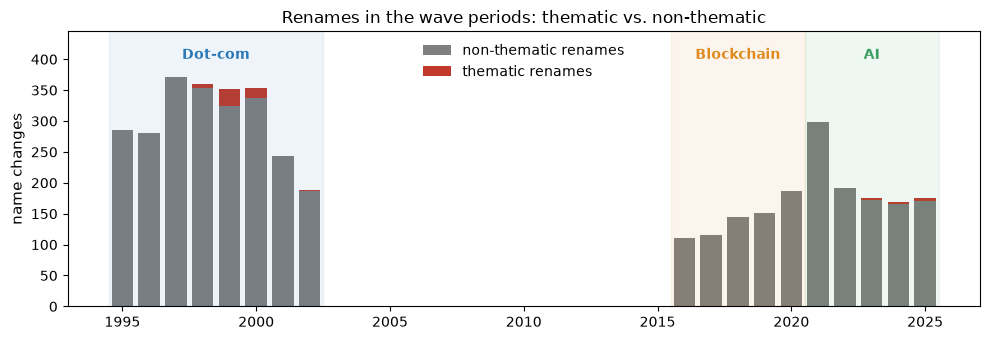

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
per_year = sample.groupby(["year", "group"]).size().unstack().reindex(columns=groups).fillna(0)
ax.bar(per_year.index, per_year["non-thematic"], color=group_colors["non-thematic"], label="non-thematic renames")
ax.bar(per_year.index, per_year["thematic"], bottom=per_year["non-thematic"], color=group_colors["thematic"],
       label="thematic renames")
ymax = (per_year["non-thematic"] + per_year["thematic"]).max()
ax.set_ylim(0, ymax * 1.2)                  # headroom so labels never touch the bars
for theme, (first, last) in wave_periods.items():
    ax.axvspan(first - 0.5, last + 0.5, color=theme_colors[theme], alpha=0.08)
    ax.text((first + last) / 2, ymax * 1.08, theme, ha="center", color=theme_colors[theme], weight="bold")
ax.set(title="Renames in the wave periods: thematic vs. non-thematic", ylabel="name changes", xlabel="")
ax.legend(frameon=False, loc="upper center")   # the empty years 2003-2015 hold the legend
fig.tight_layout()
fig.savefig(output_dir / "cg_sample_per_year.png", dpi=150)
plt.show()

## Step 3: Firm characteristics and exploratory data analysis
CRSP characteristics strictly before the effective date (`es.build_crsp_characteristics`, no fallbacks): log market
cap, price, pre-event buy-and-hold return and return volatility over [−250, −30]. Following Tutorial 4, price is
log-transformed and the regressions later impute missing values with the median and standardise.

**What to look for:** if thematic renamers are much smaller or more volatile than other renamers, a raw
difference in CARs could reflect firm type rather than the buzzword. Steps 6 and 7 control for this.

In [8]:
crsp_columns = ["log_market_cap", "price", "penny_stock", "pre_event_volatility", "pre_event_return"]
characteristics = es.build_crsp_characteristics(sample, daily, market, date_column="effective_date")
sample = sample.merge(characteristics, on="event_id", how="left")
# Fama-French 12 industry: CRSP SIC for the controls; for thematic events the classification of notebook 03
# (which replaces a SPAC shell's SIC 6799 by the merged company's Compustat SIC)
thematic_industry = pd.read_excel(output_dir / "core_analysis_results.xlsx", sheet_name="A_event_level",
                                  usecols=["event_id", "industry"])
sample["industry"] = sample["siccd"].map(es.ff12_industry)
sample = sample.merge(thematic_industry.rename(columns={"industry": "industry_nb03"}), on="event_id", how="left")
sample["industry"] = sample["industry_nb03"].fillna(sample["industry"])
sample = sample.drop(columns="industry_nb03")
sample["log_price"] = np.log(sample["price"])
plain = sample[sample["is_spac"] == 0]      # non-SPAC renames: the main comparison
plain.groupby(["theme", "group"])[crsp_columns].median().reindex(themes, level=0).round(3)

log_market_cap  price  penny_stock  pre_event_volatility  pre_event_return
theme      group                                                                                   
Dot-com    non-thematic          11.276  8.953          0.0                 0.044             0.048
           thematic              11.012  5.312          0.0                 0.088             0.433
Blockchain non-thematic          12.330  7.380          0.0                 0.037            -0.021
           thematic              10.021  3.180          1.0                 0.045            -0.003
AI         non-thematic          11.896  6.320          0.0                 0.047            -0.091
           thematic              10.778  1.775          1.0                 0.105            -0.699

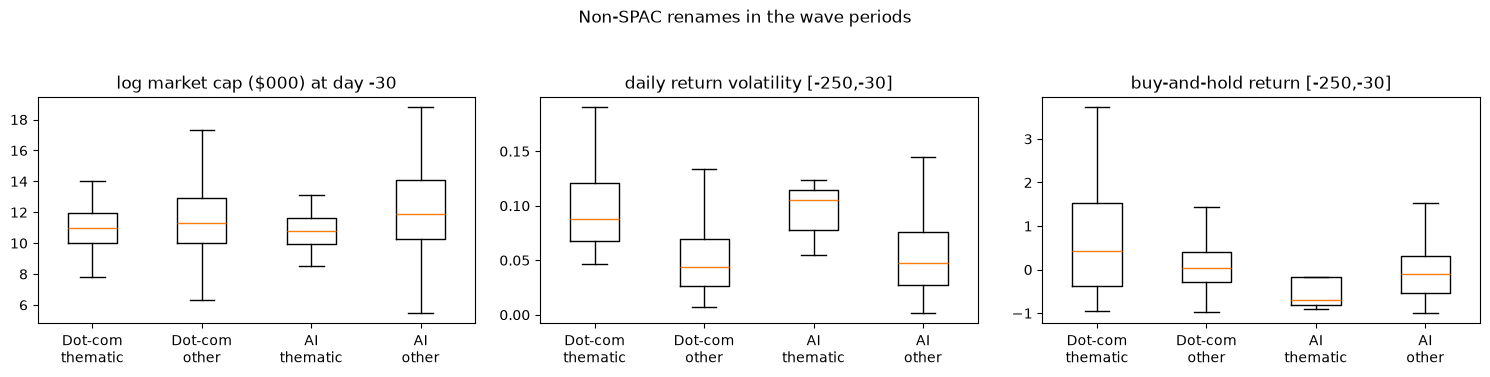

wave,AI,Dot-com
characteristic,,
log_market_cap,0.0991,0.1259
log_price,0.0170,0.0223
pre_event_return,0.1017,0.0076
pre_event_volatility,0.0010,0.0000


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, column, title in zip(axes, ["log_market_cap", "pre_event_volatility", "pre_event_return"],
                             ["log market cap ($000) at day -30", "daily return volatility [-250,-30]",
                              "buy-and-hold return [-250,-30]"]):
    data = [plain.loc[(plain["theme"] == t) & (plain["group"] == g), column].dropna()
            for t in ["Dot-com", "AI"] for g in groups]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, 5), ["Dot-com\nthematic", "Dot-com\nother", "AI\nthematic", "AI\nother"])
    ax.set_title(title)
fig.suptitle("Non-SPAC renames in the wave periods")
fig.tight_layout(rect=(0, 0, 1, 0.93))       # keep the overall title clear of the panel titles
fig.savefig(output_dir / "cg_eda_characteristics.png", dpi=150, bbox_inches="tight")
plt.show()
mann_whitney = pd.DataFrame([{"wave": t, "characteristic": c,
                              "p_value": stats.mannwhitneyu(plain.loc[(plain["theme"] == t) & (plain["group"] == "thematic"), c].dropna(),
                                                            plain.loc[(plain["theme"] == t) & (plain["group"] == "non-thematic"), c].dropna()).pvalue}
                             for t in ["Dot-com", "AI"] for c in ["log_market_cap", "pre_event_volatility", "pre_event_return", "log_price"]])
mann_whitney.pivot(index="characteristic", columns="wave", values="p_value").round(4)

### Industry mix of thematic and control renames (Fama-French 12)
If thematic renamers come mostly from tech while generic renamers come from all sectors, part of a "buzzword
premium" could be a sector effect. The table shows the industry shares of both groups (non-SPAC renames); Step 6
adds industry fixed effects and Step 7 matches within the same industry.

In [10]:
plain_waves = plain[plain["theme"].isin(["Dot-com", "AI"])]
industry_mix = (plain_waves.groupby(["theme", "group"])["industry"].value_counts(normalize=True)
                .rename("share").reset_index()
                .pivot_table(index="industry", columns=["theme", "group"], values="share", fill_value=0))
industry_mix = industry_mix.reindex(columns=pd.MultiIndex.from_product([["Dot-com", "AI"], groups])).fillna(0)
display((industry_mix * 100).round(1))
industry_mix = industry_mix.reset_index()
industry_mix.columns = [" ".join(c).strip() if isinstance(c, tuple) else c for c in industry_mix.columns]

Dot-com                    AI             
                                                   thematic non-thematic thematic non-thematic
industry                                                                                      
BusEq Business equipment (computers, software, ...     50.0         19.4     50.0         12.6
Chems Chemicals                                         0.0          1.1      0.0          1.1
Durbl Consumer durables                                 2.0          1.9     25.0          1.7
Enrgy Energy                                            0.0          4.6      0.0          4.2
Hlth Healthcare                                         4.0          8.0      0.0         19.8
Manuf Manufacturing                                     6.0          6.4     12.5          6.5
Money Finance                                           6.0         20.1      0.0         16.2
NoDur Consumer non-durables                             2.0          4.2      0.0          2.4
Other                                                  12.0         16.6     12.5         23.1
Shops Wholesale, retail, services                      12.0         10.0      0.0          7.4
Telcm Telecom                                           6.0          4.4      0.0          2.9
Unclassified                                            0.0          0.0      0.0          1.2
Utils Utilities                                         0.0          3.6      0.0          1.1

## Step 4: Event study on the CRSP effective date
Same engine as notebooks 03 and 04 (`buzzword_event_study.py`): market calendar, complete windows, pre-event
baselines only.

In [11]:
def summarise_by_group(cars, measures=("car_m1_p1", "car_m5_p5", "car_m10_p10", "cav_m1_p1")):
    """
    Run the event-study tests separately for every wave x group x (non-SPAC / de-SPAC) cell.

    Parameters
    ----------
    cars : pandas.DataFrame
        Event-level CAR table with ``theme`` and ``group``.
    measures : tuple of str

    Returns
    -------
    pandas.DataFrame
    """
    rows = []
    for stratum, spac_flag in [("non-SPAC", 0), ("de-SPAC", 1)]:
        for theme in themes + ["All waves"]:
            for group in groups:
                cell = cars[(cars["group"] == group) & (cars["is_spac"] == spac_flag)
                            & ((cars["theme"] == theme) | (theme == "All waves"))]
                if cell.empty:
                    continue
                for measure in measures:
                    rows.append({"stratum": stratum, "wave": theme, "group": group, "measure": measure,
                                 **es.test_event_sample(cell, measure)})
    return pd.DataFrame(rows)


car_keep = ["event_id", "permno", "theme", "event_date", "effective_date", "old_name", "new_name",
            "is_spac", "in_wave_period"]
abnormal, estimates, _ = es.compute_abnormal_returns(sample, daily, market, "market_model", "effective_date")
cars = es.compute_cars(abnormal, estimates, sample, keep_columns=car_keep).merge(
    sample[["event_id", "group", "year", "industry", "log_market_cap", "log_price", "penny_stock", "pre_event_volatility",
            "pre_event_return"]], on="event_id")
group_summary = summarise_by_group(cars)
print("events with a CAR:", cars.groupby(["theme", "group", "is_spac"]).size().to_dict())
print("dropped:", estimates["dropped_reason"].value_counts().to_dict())
group_summary[group_summary["measure"].isin(["car_m1_p1", "car_m5_p5", "cav_m1_p1"])
              & (group_summary["wave"] != "All waves")].round(4)

events with a CAR: {('AI', 'non-thematic', 0): 665, ('AI', 'non-thematic', 1): 333, ('AI', 'thematic', 0): 8, ('AI', 'thematic', 1): 5, ('Blockchain', 'non-thematic', 0): 601, ('Blockchain', 'non-thematic', 1): 106, ('Blockchain', 'thematic', 0): 2, ('Dot-com', 'non-thematic', 0): 2374, ('Dot-com', 'non-thematic', 1): 8, ('Dot-com', 'thematic', 0): 50}
dropped: {'': 4152, 'no trade within 2 sessions of day 0': 3}


,stratum,wave,group,measure,n,mean,median,pct_positive,ci_low,ci_high,mde_80,t_pvalue,sign_pvalue,wilcoxon_pvalue,n_bmp,bmp_t,bmp_pvalue,boot_ci_low,boot_ci_high,boot_pvalue
0,non-SPAC,Dot-com,thematic,car_m1_p1,50,0.0240,-0.0215,46.0000,-0.0264,0.0743,0.0716,0.3431,0.6718,0.6947,48.0,0.7987,0.4285,-0.0220,0.0763,0.3413
1,non-SPAC,Dot-com,thematic,car_m5_p5,49,0.1012,0.0231,55.1020,-0.0029,0.2052,0.1480,0.0564,0.5682,0.1448,48.0,2.0030,0.0510,0.0023,0.2049,0.0492
3,non-SPAC,Dot-com,thematic,cav_m1_p1,48,2.2370,2.2251,64.5833,0.4366,4.0375,2.5605,0.0160,0.0595,0.0048,NaN,NaN,NaN,0.4672,3.9762,0.0137
4,non-SPAC,Dot-com,non-thematic,car_m1_p1,2304,0.0054,0.0007,50.4340,0.0008,0.0100,0.0066,0.0220,0.6922,0.2724,2280.0,3.7879,0.0002,0.0008,0.0101,0.0237
5,non-SPAC,Dot-com,non-thematic,car_m5_p5,2301,-0.0049,-0.0083,46.9361,-0.0121,0.0022,0.0102,0.1761,0.0035,0.0024,2278.0,0.4122,0.6802,-0.0119,0.0023,0.1745
7,non-SPAC,Dot-com,non-thematic,cav_m1_p1,2282,0.7216,0.5915,56.7046,0.5216,0.9215,0.2858,0.0000,0.0000,0.0000,NaN,NaN,NaN,0.5176,0.9226,0.0000
8,non-SPAC,Blockchain,thematic,car_m1_p1,2,-0.1179,-0.1179,50.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,non-SPAC,Blockchain,thematic,car_m5_p5,2,0.0921,0.0921,50.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,non-SPAC,Blockchain,thematic,cav_m1_p1,2,9.7846,9.7846,100.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,non-SPAC,Blockchain,non-thematic,car_m1_p1,585,-0.0141,-0.0017,48.7179,-0.0266,-0.0016,0.0179,0.0272,0.5627,0.1476,579.0,-0.6528,0.5142,-0.0268,-0.0015,0.0291


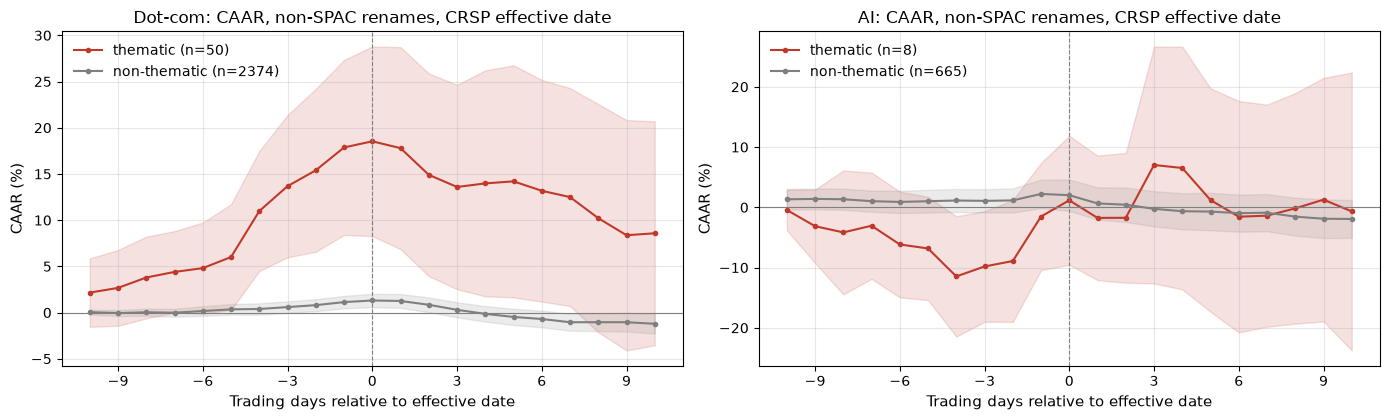

In [12]:
def plot_thematic_vs_control(abnormal, events, file_name, waves=("Dot-com", "AI")):
    """
    Plot the cumulative average abnormal return (95% CI) of thematic vs. non-thematic renames per wave.

    Parameters
    ----------
    abnormal : pandas.DataFrame
    events : pandas.DataFrame
        Needs ``event_id``, ``theme`` and ``group``.
    file_name : str
    waves : tuple of str
    """
    data = abnormal.merge(events[["event_id", "theme", "group"]], on="event_id")
    fig, axes = plt.subplots(1, len(waves), figsize=(7 * len(waves), 4.3), sharey=False)
    for ax, theme in zip(axes, waves):
        for group in groups:
            sub = data[(data["theme"] == theme) & (data["group"] == group)]
            wide = sub.pivot(index="event_id", columns="relative_day", values="abnormal_return").fillna(0)
            cum = wide.cumsum(axis=1)
            mean, se = cum.mean() * 100, cum.std() / np.sqrt(len(cum)) * 100
            ax.plot(mean.index, mean, marker="o", ms=3, color=group_colors[group], label=f"{group} (n={len(cum)})")
            ax.fill_between(mean.index, mean - 1.96 * se, mean + 1.96 * se, color=group_colors[group], alpha=0.15)
        ax.axvline(0, color="grey", lw=0.8, ls="--")
        ax.axhline(0, color="grey", lw=0.8)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set(title=f"{theme}: CAAR, non-SPAC renames, CRSP effective date", xlabel="Trading days relative to effective date",
               ylabel="CAAR (%)")
        ax.grid(alpha=0.3)
        ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(output_dir / file_name, dpi=150)
    plt.show()


plot_thematic_vs_control(abnormal, sample[sample["is_spac"] == 0], "cg_caar_thematic_vs_control.png")

## Step 5: Thematic − non-thematic, per wave
For each wave and window:
* **bootstrap** of the difference in means (10,000 draws, each group resampled separately), with a 95%
  percentile interval and a two-sided p-value;
* **Welch t-test** (unequal variances) and **Mann-Whitney U** (difference in distributions, robust to the fat
  tails of small-cap returns).

Two specifications:
* **A (main):** thematic cosmetic renames and pivots vs. non-SPAC control renames, both on the CRSP effective date;
* **B:** thematic de-SPAC closings vs. SPAC-related control renames, both on the CRSP effective date.

In [13]:
def compare_groups(treated, control, outcome, n_draws=es.N_BOOTSTRAP):
    """
    Compare the mean outcome of thematic and non-thematic renames.

    Parameters
    ----------
    treated, control : pandas.Series
        Outcome values of the two groups.
    outcome : str
        Name of the outcome (for the output row).
    n_draws : int

    Returns
    -------
    dict
        Group means and medians, the difference, bootstrap CI / p-value, Welch t and Mann-Whitney p-values.
    """
    x, y = treated.dropna().to_numpy(), control.dropna().to_numpy()
    row = {"outcome": outcome, "n_thematic": len(x), "n_control": len(y), "mean_thematic": x.mean() if len(x) else np.nan,
           "mean_control": y.mean(), "median_thematic": np.median(x) if len(x) else np.nan, "median_control": np.median(y)}
    row["difference"] = row["mean_thematic"] - row["mean_control"]
    if len(x) < 3:
        return row
    draws = rng.choice(x, (n_draws, len(x))).mean(axis=1) - rng.choice(y, (n_draws, len(y))).mean(axis=1)
    row.update(boot_ci_low=np.percentile(draws, 2.5), boot_ci_high=np.percentile(draws, 97.5),
               boot_pvalue=(np.abs(draws - row["difference"]) >= abs(row["difference"])).mean(),
               welch_pvalue=stats.ttest_ind(x, y, equal_var=False).pvalue,
               mannwhitney_pvalue=stats.mannwhitneyu(x, y).pvalue)
    return row


comparison_rows = []
specifications = {
    "A: cosmetic/pivot vs non-SPAC renames, effective date": (cars[(cars["group"] == "thematic") & (cars["is_spac"] == 0)],
                                                              cars[(cars["group"] == "non-thematic") & (cars["is_spac"] == 0)]),
    "B: de-SPAC closings vs SPAC-related renames, effective date": (cars[(cars["group"] == "thematic") & (cars["is_spac"] == 1)],
                                                                    cars[(cars["group"] == "non-thematic") & (cars["is_spac"] == 1)]),
}
for spec, (thematic_cars, control_cars) in specifications.items():
    for theme in themes + ["Dot-com + AI"]:
        in_wave = (lambda d: d["theme"].isin(["Dot-com", "AI"])) if theme == "Dot-com + AI" else (lambda d: d["theme"] == theme)
        for outcome in ["car_m1_p1", "car_m5_p5", "car_m10_p10", "cav_m1_p1"]:
            comparison_rows.append({"specification": spec, "wave": theme,
                                    **compare_groups(thematic_cars.loc[in_wave(thematic_cars), outcome],
                                                     control_cars.loc[in_wave(control_cars), outcome], outcome)})
group_differences = pd.DataFrame(comparison_rows)
group_differences = group_differences[group_differences["n_thematic"] > 0].reset_index(drop=True)
group_differences[group_differences["outcome"].isin(["car_m1_p1", "car_m5_p5", "cav_m1_p1"])
                  & (group_differences["wave"] != "Blockchain")].round(4)

,specification,wave,outcome,n_thematic,n_control,mean_thematic,mean_control,median_thematic,median_control,difference,boot_ci_low,boot_ci_high,boot_pvalue,welch_pvalue,mannwhitney_pvalue
0,"A: cosmetic/pivot vs non-SPAC renames, effecti...",Dot-com,car_m1_p1,50,2304,0.0240,0.0054,-0.0215,0.0007,0.0186,-0.0273,0.0712,0.4656,0.4633,0.6637
1,"A: cosmetic/pivot vs non-SPAC renames, effecti...",Dot-com,car_m5_p5,49,2301,0.1012,-0.0049,0.0231,-0.0083,0.1061,0.0086,0.2081,0.0382,0.0463,0.0578
3,"A: cosmetic/pivot vs non-SPAC renames, effecti...",Dot-com,cav_m1_p1,48,2282,2.2370,0.7216,2.2251,0.5915,1.5155,-0.2659,3.1987,0.0851,0.0989,0.0389
8,"A: cosmetic/pivot vs non-SPAC renames, effecti...",AI,car_m1_p1,8,638,0.0716,-0.0046,0.0504,-0.0106,0.0762,-0.0520,0.2279,0.2969,0.3571,0.1452
9,"A: cosmetic/pivot vs non-SPAC renames, effecti...",AI,car_m5_p5,8,635,0.0737,-0.0120,0.0689,-0.0149,0.0856,-0.1239,0.2972,0.4367,0.4771,0.5806
11,"A: cosmetic/pivot vs non-SPAC renames, effecti...",AI,cav_m1_p1,8,631,5.2224,1.3271,5.2392,0.5616,3.8952,0.6583,6.9770,0.0171,0.0595,0.0157
12,"A: cosmetic/pivot vs non-SPAC renames, effecti...",Dot-com + AI,car_m1_p1,58,2942,0.0305,0.0032,0.0022,-0.0017,0.0273,-0.0173,0.0753,0.2469,0.2602,0.7507
13,"A: cosmetic/pivot vs non-SPAC renames, effecti...",Dot-com + AI,car_m5_p5,57,2936,0.0973,-0.0065,0.0231,-0.0100,0.1037,0.0134,0.1964,0.0241,0.0316,0.0472
15,"A: cosmetic/pivot vs non-SPAC renames, effecti...",Dot-com + AI,cav_m1_p1,56,2913,2.6635,0.8527,2.8438,0.5875,1.8108,0.2442,3.4041,0.0261,0.0309,0.0056
16,"B: de-SPAC closings vs SPAC-related renames, e...",AI,car_m1_p1,5,316,-0.5145,-0.0725,-0.6187,-0.0466,-0.4420,-0.6946,-0.1792,0.0000,0.0362,0.0075


## Step 6: Regression with a thematic dummy
$$CAR_i = \alpha + \beta\,Thematic_i + \sum_t \delta_t\,Year_{t,i} + \gamma' X_i + \varepsilon_i$$
estimated on non-SPAC renames per wave (Dot-com, AI) and pooled (year dummies also absorb the wave, because the
waves do not overlap in time), and for AI also on de-SPACs only and on all AI renames with a de-SPAC dummy.
* **β is the buzzword premium**: the extra abnormal return of a thematic rename over a generic rename of the
  same year with similar firm characteristics.
* Models: (1) dummy only; (2) + year fixed effects; (3) + firm controls *X* (log market cap, log price,
  pre-event return, pre-event volatility); (6) = (3) + Fama-French 12 industry fixed effects (Fama & French, 1997); (4) = (3) with the CAR winsorised at 1%/99% (outlier treatment as in
  Tutorial 4, because a few control renames have CARs of several hundred percent); (5) = (3) with the
  standardised CAR (BMP-style, also winsorised), so that very volatile penny stocks do not dominate.
* Preprocessing as in Tutorial 4: a `ColumnTransformer` with `OneHotEncoder` (year, first category dropped),
  `SimpleImputer(median)` + `StandardScaler` (controls) and the dummy passed through. Inference: OLS with HC3
  robust standard errors.

In [14]:
control_columns = ["log_market_cap", "log_price", "pre_event_return", "pre_event_volatility"]


def winsorize(series, lower=0.01, upper=0.99):
    """
    Clip a series at its 1st and 99th percentiles.

    Parameters
    ----------
    series : pandas.Series
    lower, upper : float

    Returns
    -------
    pandas.Series
    """
    return series.clip(series.quantile(lower), series.quantile(upper))


def build_thematic_design(data, year_effects, controls, industry_effects=False):
    """
    Build the regression design matrix with the Tutorial 4 preprocessing pipeline.

    Parameters
    ----------
    data : pandas.DataFrame
        Events of one or more waves with ``group``, ``year`` and the controls.
    year_effects : bool
        Add year dummies (first year dropped).
    controls : list of str
        Numeric controls (empty list = none).
    industry_effects : bool
        Add Fama-French 12 industry dummies (first category dropped).

    Returns
    -------
    pandas.DataFrame
        Design matrix incl. a constant.
    """
    data = data.assign(thematic=(data["group"] == "thematic").astype(float), year=data["year"].astype(str))
    transformers = [("dummy", "passthrough", ["thematic"])]
    if year_effects:
        transformers.append(("year", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), ["year"]))
    if industry_effects:
        transformers.append(("industry", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"),
                             ["industry"]))
    if controls:
        transformers.append(("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), controls))
        if data["is_spac"].nunique() > 1:      # mixed samples: de-SPAC dummy
            transformers.append(("flag", "passthrough", ["is_spac"]))
    design = ColumnTransformer(transformers, verbose_feature_names_out=False).fit_transform(data)
    return sm.add_constant(design.astype(float))


def fit_thematic_models(samples, outcomes=("car_m1_p1", "car_m5_p5", "cav_m1_p1")):
    """
    Estimate models (1)-(5) of the thematic premium for each sample and outcome.

    Parameters
    ----------
    samples : dict of pandas.DataFrame
        Sample label -> event-level CAR table (thematic and non-thematic renames).
    outcomes : tuple of str

    Returns
    -------
    pandas.DataFrame
        Coefficient of the thematic dummy, HC3 standard error, p-value, N and R² per model.
    """
    specs = {"(1) dummy only": (False, []), "(2) + year FE": (True, []),
             "(3) + year FE + controls": (True, control_columns),
             "(6) = (3) + industry FE (FF12)": (True, control_columns)}
    rows = []
    for label, data in samples.items():
        for outcome in outcomes:
            model_specs = dict(specs)
            if outcome.startswith("car"):
                model_specs["(4) = (3), winsorised CAR"] = (True, control_columns)
                model_specs["(5) = (3), standardised CAR"] = (True, control_columns)
            for model, (year_effects, controls) in model_specs.items():
                y_column = outcome.replace("car", "scar") if model.startswith("(5)") else outcome
                sub = data.dropna(subset=[y_column]).reset_index(drop=True)
                y = winsorize(sub[y_column]) if model.startswith(("(4)", "(5)")) else sub[y_column]
                design = build_thematic_design(sub, year_effects, controls, industry_effects=model.startswith("(6)"))
                results = sm.OLS(y.astype(float), design).fit(cov_type="HC3")
                rows.append({"sample": label, "outcome": outcome, "model": model, "coef_thematic": results.params["thematic"],
                             "robust_se": results.bse["thematic"], "p_value": results.pvalues["thematic"],
                             "n_thematic": int(sub["group"].eq("thematic").sum()), "n_obs": int(results.nobs),
                             "r_squared": results.rsquared})
    return pd.DataFrame(rows)


def regression_samples(cars):
    """
    Define the regression samples (thematic + non-thematic renames).

    Parameters
    ----------
    cars : pandas.DataFrame

    Returns
    -------
    dict of pandas.DataFrame
    """
    plain = cars[cars["is_spac"] == 0]
    return {"Dot-com, non-SPAC": plain[plain["theme"] == "Dot-com"],
            "AI, non-SPAC": plain[plain["theme"] == "AI"],
            "Dot-com + AI, non-SPAC (pooled)": plain[plain["theme"].isin(["Dot-com", "AI"])],
            "AI, de-SPACs only": cars[(cars["theme"] == "AI") & (cars["is_spac"] == 1)],
            "AI, all (+ de-SPAC dummy)": cars[cars["theme"] == "AI"]}


thematic_regressions = fit_thematic_models(regression_samples(cars))
thematic_regressions[thematic_regressions["outcome"] == "car_m1_p1"].round(4)

,sample,outcome,model,coef_thematic,robust_se,p_value,n_thematic,n_obs,r_squared
0,"Dot-com, non-SPAC",car_m1_p1,(1) dummy only,0.0186,0.0254,0.4644,50,2354,0.0005
1,"Dot-com, non-SPAC",car_m1_p1,(2) + year FE,0.0229,0.0255,0.3701,50,2354,0.0067
2,"Dot-com, non-SPAC",car_m1_p1,(3) + year FE + controls,0.0323,0.0260,0.2142,50,2354,0.0152
3,"Dot-com, non-SPAC",car_m1_p1,(6) = (3) + industry FE (FF12),0.0319,0.0259,0.2181,50,2354,0.0184
4,"Dot-com, non-SPAC",car_m1_p1,"(4) = (3), winsorised CAR",0.0245,0.0218,0.2625,50,2354,0.0173
5,"Dot-com, non-SPAC",car_m1_p1,"(5) = (3), standardised CAR",0.1264,0.1653,0.4446,48,2328,0.0088
16,"AI, non-SPAC",car_m1_p1,(1) dummy only,0.0762,0.0827,0.3571,8,646,0.0012
17,"AI, non-SPAC",car_m1_p1,(2) + year FE,0.0826,0.0849,0.3309,8,646,0.0045
18,"AI, non-SPAC",car_m1_p1,(3) + year FE + controls,0.0964,0.0821,0.2404,8,646,0.0205
19,"AI, non-SPAC",car_m1_p1,(6) = (3) + industry FE (FF12),0.1011,0.0855,0.2370,8,646,0.0335


## Step 7: Size-matched controls
The regression adjusts for size linearly. As a non-parametric check, each thematic rename is paired with the
**3 non-thematic renames of the same wave, calendar year and stratum whose log market cap is closest**,
**without replacement** (each control is used once), so the paired differences are independent of each other.
A second matching additionally requires the **same Fama-French 12 industry**.
The test is then on the paired differences $d_i = CAR_i - \overline{CAR}_{matched(i)}$: t-test, Wilcoxon and
bootstrap.

In [15]:
def size_matched_differences(cars, n_matches=n_matched_controls, same_industry=False):
    """
    Pair each thematic rename with its nearest-size non-thematic renames of the same wave and year.

    Parameters
    ----------
    cars : pandas.DataFrame
    n_matches : int
    same_industry : bool
        Also require the same Fama-French 12 industry.

    Returns
    -------
    pandas.DataFrame
        One row per thematic event: its CARs, the mean CARs of its matches and the differences.
    """
    treated = cars[cars["group"] == "thematic"].dropna(subset=["log_market_cap"])
    pool = cars[cars["group"] == "non-thematic"].dropna(subset=["log_market_cap"])
    used = set()                     # each control is used for at most one thematic event
    rows = []
    for event in treated.sort_values("effective_date").itertuples():
        candidates = pool[(pool["theme"] == event.theme) & (pool["year"] == event.year)
                          & (pool["is_spac"] == event.is_spac) & ~pool["event_id"].isin(used)]
        if same_industry:
            candidates = candidates[candidates["industry"] == event.industry]
        if len(candidates) < n_matches:
            continue
        matches = candidates.iloc[(candidates["log_market_cap"] - event.log_market_cap).abs().argsort()[:n_matches]]
        used.update(matches["event_id"])
        row = {"event_id": event.event_id, "theme": event.theme, "is_spac": event.is_spac, "year": event.year,
               "new_name": event.new_name,
               "size_gap": event.log_market_cap - matches["log_market_cap"].mean()}
        for outcome in ["car_m1_p1", "car_m5_p5", "cav_m1_p1"]:
            row[f"{outcome}_thematic"] = getattr(event, outcome)
            row[f"{outcome}_matched"] = matches[outcome].mean()
            row[f"{outcome}_diff"] = getattr(event, outcome) - matches[outcome].mean()
        rows.append(row)
    return pd.DataFrame(rows)


matched = pd.concat([size_matched_differences(cars).assign(matching="year + size"),
                     size_matched_differences(cars, same_industry=True).assign(matching="year + size + FF12 industry")],
                    ignore_index=True)
matched_rows = []
for (matching, theme, spac_flag), pairs in matched.groupby(["matching", "theme", "is_spac"]):
    for outcome in ["car_m1_p1", "car_m5_p5", "cav_m1_p1"]:
        result = es.test_event_sample(pairs.rename(columns={f"{outcome}_diff": "difference"}), "difference")
        matched_rows.append({"matching": matching, "wave": theme, "stratum": "de-SPAC" if spac_flag else "non-SPAC",
                             "outcome": outcome, **result})
matched_summary = pd.DataFrame(matched_rows)
print("mean size gap (log points) thematic - matched:",
      matched.groupby(["matching", "theme", "is_spac"])["size_gap"].mean().round(3).to_dict())
matched_summary.round(4)

mean size gap (log points) thematic - matched: {('year + size', 'AI', 0): -0.005, ('year + size', 'AI', 1): 0.005, ('year + size', 'Blockchain', 0): 0.014, ('year + size', 'Dot-com', 0): 0.007, ('year + size + FF12 industry', 'AI', 0): 0.007, ('year + size + FF12 industry', 'AI', 1): -1.063, ('year + size + FF12 industry', 'Blockchain', 0): 0.015, ('year + size + FF12 industry', 'Dot-com', 0): -0.11}


,matching,wave,stratum,outcome,n,mean,median,pct_positive,ci_low,ci_high,mde_80,t_pvalue,sign_pvalue,wilcoxon_pvalue,boot_ci_low,boot_ci_high,boot_pvalue
0,year + size,AI,non-SPAC,car_m1_p1,8,0.0525,0.0687,62.5000,-0.2263,0.3312,0.3844,0.6698,0.7266,0.5469,NaN,NaN,NaN
1,year + size,AI,non-SPAC,car_m5_p5,8,0.0969,0.1904,62.5000,-0.2488,0.4425,0.4766,0.5287,0.7266,0.4609,NaN,NaN,NaN
2,year + size,AI,non-SPAC,cav_m1_p1,8,3.0114,3.6130,62.5000,-3.5716,9.5945,9.0776,0.3152,0.7266,0.3828,NaN,NaN,NaN
3,year + size,AI,de-SPAC,car_m1_p1,5,-0.6726,-0.6240,0.0000,-1.1778,-0.1673,0.6765,0.0209,0.0625,0.0625,NaN,NaN,NaN
4,year + size,AI,de-SPAC,car_m5_p5,5,-0.5712,-0.5630,0.0000,-0.8891,-0.2534,0.4255,0.0075,0.0625,0.0625,NaN,NaN,NaN
5,year + size,AI,de-SPAC,cav_m1_p1,5,0.7265,2.0231,80.0000,-7.1324,8.5853,10.5223,0.8101,0.3750,0.6250,NaN,NaN,NaN
6,year + size,Blockchain,non-SPAC,car_m1_p1,2,-0.1417,-0.1417,50.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,year + size,Blockchain,non-SPAC,car_m5_p5,2,0.0836,0.0836,50.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,year + size,Blockchain,non-SPAC,cav_m1_p1,2,12.4183,12.4183,100.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,year + size,Dot-com,non-SPAC,car_m1_p1,49,0.0289,-0.0319,38.7755,-0.0252,0.0829,0.0769,0.2885,0.1524,0.8592,-0.0208,0.0847,0.2713


## Step 8: Export

In [16]:
with pd.ExcelWriter(output_dir / "control_group_results.xlsx") as writer:
    for sheet, table in {"control_funnel": control_funnel, "event_level": cars,
                         "summary_by_group": group_summary, "thematic_minus_control": group_differences,
                         "regressions_effective_date": thematic_regressions,
                         "size_matched_pairs": matched, "size_matched_tests": matched_summary,
                         "characteristics_mannwhitney": mann_whitney, "industry_mix": industry_mix,
                         "estimation": estimates}.items():
        table.to_excel(writer, sheet_name=sheet[:31], index=False)
sample.to_csv(processed_dir / "control_group_events.csv", index=False)
print("results written to", output_dir / "control_group_results.xlsx")

results written to /Users/chunhanliao/Documents/FS_MADS/1_IntroDA/Group Project/IDA_Group7_whats_in_a_buzzword_submission/output/control_group_results.xlsx


In [17]:
# Key numbers for the summary below
key = group_differences[group_differences["outcome"].isin(["car_m1_p1", "car_m5_p5"]) & group_differences["wave"].isin(["Dot-com", "AI"])]
display(key[["specification", "wave", "outcome", "n_thematic", "n_control", "mean_thematic", "mean_control", "difference",
             "boot_ci_low", "boot_ci_high", "boot_pvalue", "mannwhitney_pvalue"]].round(4))
thematic_regressions[thematic_regressions["outcome"].isin(["car_m1_p1", "car_m5_p5"])].pivot_table(
    index=["sample", "model"], columns="outcome", values=["coef_thematic", "p_value"], sort=False).round(4)

,specification,wave,outcome,n_thematic,n_control,mean_thematic,mean_control,difference,boot_ci_low,boot_ci_high,boot_pvalue,mannwhitney_pvalue
0,"A: cosmetic/pivot vs non-SPAC renames, effecti...",Dot-com,car_m1_p1,50,2304,0.0240,0.0054,0.0186,-0.0273,0.0712,0.4656,0.6637
1,"A: cosmetic/pivot vs non-SPAC renames, effecti...",Dot-com,car_m5_p5,49,2301,0.1012,-0.0049,0.1061,0.0086,0.2081,0.0382,0.0578
8,"A: cosmetic/pivot vs non-SPAC renames, effecti...",AI,car_m1_p1,8,638,0.0716,-0.0046,0.0762,-0.0520,0.2279,0.2969,0.1452
9,"A: cosmetic/pivot vs non-SPAC renames, effecti...",AI,car_m5_p5,8,635,0.0737,-0.0120,0.0856,-0.1239,0.2972,0.4367,0.5806
16,"B: de-SPAC closings vs SPAC-related renames, e...",AI,car_m1_p1,5,316,-0.5145,-0.0725,-0.4420,-0.6946,-0.1792,0.0000,0.0075
17,"B: de-SPAC closings vs SPAC-related renames, e...",AI,car_m5_p5,5,314,-0.5944,-0.1174,-0.4769,-0.9636,-0.1078,0.0300,0.0423


coef_thematic             p_value          
outcome                                                            car_m1_p1 car_m5_p5 car_m1_p1 car_m5_p5
sample                          model                                                                     
Dot-com, non-SPAC               (1) dummy only                        0.0186    0.1061    0.4644    0.0429
                                (2) + year FE                         0.0229    0.1189    0.3701    0.0230
                                (3) + year FE + controls              0.0323    0.1500    0.2142    0.0036
                                (6) = (3) + industry FE (FF12)        0.0319    0.1507    0.2181    0.0037
                                (4) = (3), winsorised CAR             0.0245    0.1261    0.2625    0.0033
                                (5) = (3), standardised CAR           0.1264    0.4703    0.4446    0.0048
AI, non-SPAC                    (1) dummy only                        0.0762    0.0856    0.3571    0.4826
                                (2) + year FE                         0.0826    0.0969    0.3309    0.4313
                                (3) + year FE + controls              0.0964    0.1184    0.2404    0.3228
                                (6) = (3) + industry FE (FF12)        0.1011    0.1247    0.2370    0.3056
                                (4) = (3), winsorised CAR             0.1064    0.1338    0.1838    0.2578
                                (5) = (3), standardised CAR           0.9188    0.4711    0.1556    0.2484
Dot-com + AI, non-SPAC (pooled) (1) dummy only                        0.0273    0.1037    0.2596    0.0289
                                (2) + year FE                         0.0313    0.1157    0.2016    0.0147
                                (3) + year FE + controls              0.0431    0.1472    0.0830    0.0016
                                (6) = (3) + industry FE (FF12)        0.0437    0.1485    0.0791    0.0017
                                (4) = (3), winsorised CAR             0.0393    0.1309    0.0838    0.0016
                                (5) = (3), standardised CAR           0.2447    0.4641    0.1611    0.0036
AI, de-SPACs only               (1) dummy only                       -0.4420   -0.4769    0.0071    0.0835
                                (2) + year FE                        -0.4010   -0.4622    0.0004    0.0778
                                (3) + year FE + controls             -0.3764   -0.4238    0.0014    0.1377
                                (6) = (3) + industry FE (FF12)       -0.2750   -0.3012    0.0443    0.3039
                                (4) = (3), winsorised CAR            -0.3570   -0.4140    0.0017    0.1408
                                (5) = (3), standardised CAR         -24.4462   -9.2093    0.2193    0.5906
AI, all (+ de-SPAC dummy)       (1) dummy only                       -0.1267   -0.1364    0.2602    0.3690
                                (2) + year FE                        -0.1296   -0.1377    0.2353    0.3620
                                (3) + year FE + controls             -0.1175   -0.1212    0.2351    0.3855
                                (6) = (3) + industry FE (FF12)       -0.1045   -0.1071    0.2914    0.4388
                                (4) = (3), winsorised CAR            -0.0928   -0.0935    0.3338    0.4706
                                (5) = (3), standardised CAR         -11.8835   -6.4417    0.1033    0.2267

## Summary (numbers from the run above)
**Control group.** 4,090 non-thematic name changes of listed common stocks fall in the wave periods (Dot-com
2,383, Blockchain 708, AI 999; 448 SPAC-related). They are compared with the in-wave thematic renames that are
cosmetic renames or pivots (Dot-com 50, AI 8, Blockchain 2 with a CAR) and, separately, with the 5 AI de-SPAC
closings. **Both groups are on the CRSP effective date**, so this is an implementation-date comparison.

**A generic rename hardly moves the price:** non-SPAC control renames earn a mean CAR[−1,+1] of +0.5% in the
Dot-com years and −0.5% in the AI years.

**Dot-com (thematic − control, effective date).**
* CAR[−1,+1]: +1.9 pp (95% CI −2.7 to +7.1, bootstrap p = 0.47): no premium on the effective day itself.
* CAR[−5,+5]: **+10.6 pp** (CI +0.9 to +20.8, p = 0.04); with year fixed effects and controls +15.0 pp
  (HC3 p = 0.004). Size-matched pairs (3 controls per event, no reuse): +14.1 pp (bootstrap p = 0.005).
* Reading: the effective date often comes after the news, so the 3-day window misses most of the reaction;
  the wider window still shows thematic Dot-com renames out-performing generic renames of the same years.

**Industry.** Thematic renamers are concentrated in business equipment (Dot-com 50% vs. 19% of control renames;
AI 50% vs. 13%). Adding Fama-French 12 industry fixed effects leaves the Dot-com premium unchanged (CAR[−5,+5]
+15.1 pp, p = 0.004; CAR[−1,+1] +3.2 pp, p = 0.22), and matching on year, size **and** industry gives +12.4 pp
over [−5,+5] (bootstrap p = 0.02). The premium is therefore not a tech-sector effect.

**AI.** Cosmetic/pivot AI renames (n = 8): +7.6 pp vs. controls over [−1,+1] (p = 0.30), with a wide interval;
abnormal volume is clearly higher (+3.9 log points, p = 0.02). The 5 AI de-SPAC closings lose −51% over
[−1,+1] vs. −7% for SPAC-related control renames (difference −44 pp, p < 0.001): the strongly negative AI
reactions come from **de-SPAC closings**, not from AI names.

**Limits.** Controls cannot be hand-coded for deal type; control renames after ordinary mergers stay in the pool.
Blockchain cannot be tested (2 in-wave renames).